# Day 17 · Part 2: Training the Neural Network, from Data to Predictions

**Day 17 is about training a neural network with PyTorch.** [Part 1](Notebook.ipynb) built `CustomerPredictor`, a small network with 3 inputs and 1 output, and looked inside it. This notebook trains it, in five stages:

1. **Prepare the data:** create, split and scale a customer dataset, convert it to tensors and cut it into mini-batches.
2. **Set up the model, the loss function and the optimiser.**
3. **Train the model**, checking it on validation data after every epoch and keeping the best weights.
4. **Evaluate the model** on test customers it has never seen.
5. **Use the model** to predict for a new customer.

![Day 17 roadmap. Part 2, this notebook, is highlighted: it trains the network in five stages, prepare the data (sections 1 to 6: libraries, create, split, scale, tensors, mini-batches), set up the model, loss and optimiser (sections 7 to 8), train (section 9), evaluate on the test set (section 10) and predict for a new customer (section 11). Part 1 built the network.](images/day17_roadmap_part2.svg)

### How to use this notebook
- Run the cells **from top to bottom**. Each step uses the variables made by the step before it (`features`, `train_features`, `train_features_scaled`, ...).
- Each section follows the same pattern: **the idea → the code → what the output means**.
- The diagrams are in the `images/` folder.
- The `# Stage` headings match the five stages in the roadmap above. The numbered sections inside them run from 1 to 11.

### Contents

| Stage | Section | What you will learn |
|---|---|---|
| **1. Prepare the data** | 1. Importing the Libraries | Which library does which job |
| | 2. Creating the Dataset | A practice dataset of 1000 customers with `make_classification` |
| | 3. Splitting the Data into Training, Validation and Test Sets | Why the data is split three ways |
| | 4. Scaling the Features with `StandardScaler` | Scaling, and `fit_transform` vs `transform` |
| | 5. Converting the Data to PyTorch Tensors | What a tensor is, `float32`, the `(n, 1)` label shape, and why the input must be 2D |
| | 6. Creating Mini-batches with `TensorDataset` and `DataLoader` | Batches, iterations, epochs and shuffling |
| **2. Set up the model** | 7. Creating the Model | The same `CustomerPredictor` as in Part 1 |
| | 8. Choosing the Loss Function and the Optimiser | Binary cross-entropy, and how AdamW updates the weights |
| **3. Train the model** | 9. Training the Model: the Training Loop | Batch and epoch logs, validation, saving the best model, and the loss chart |
| **4. Evaluate the model** | 10. Evaluating the Model on the Test Set | Accuracy, the confusion matrix and the classification report (precision, recall, F1-score) |
| **5. Use the model** | 11. Predicting for a New Customer | The same steps for one new customer: a 2D row, scaling, a probability and a label |
| | Summary | The whole training workflow on one page |

# Stage 1 · Prepare the Data

Turn raw customer data into what the network needs: scaled `float32` tensors, split three ways and cut into mini-batches. *Sections 1–6.*

## 1. Importing the Libraries

All the tools for this notebook are imported once, at the top. Each one has one job:

| Import | Job | Used in |
|---|---|---|
| `torch`, `torch.nn` | Tensors, layers and loss functions | Sections 5, 7, 8 |
| `torch.optim` | Optimisers that update the weights (SGD, Adam) | Section 8 |
| `TensorDataset`, `DataLoader` | Cut the data into mini-batches | Section 6 |
| `make_classification` | Creates a practice dataset | Section 2 |
| `train_test_split` | Splits the data into training, validation and test sets | Section 3 |
| `StandardScaler` | Puts every feature on the same scale | Section 4 |
| `accuracy_score`, `classification_report`, `confusion_matrix` | Measure how good the predictions are | Section 10 |
| `matplotlib.pyplot` | Draws charts, such as the training loss | Sections 9, 10 |

> `torch.optim`, the metrics and `plt` are not used yet. They are needed later, when the model is trained and evaluated.

In [34]:
# PyTorch: tensors, layers, optimisers and data loading
import torch
import torch.nn as nn  # layers (nn.Linear) and loss functions
import torch.optim as optim  # optimisers that update the weights (e.g. SGD, Adam)
from torch.utils.data import (
    DataLoader,
    TensorDataset,
)  # feed the data to the model in mini-batches

# scikit-learn: create, split, scale and score the data
from sklearn.datasets import (
    make_classification,
)  # generates a fake classification dataset
from sklearn.model_selection import (
    train_test_split,
)  # splits the data into training and test sets
from sklearn.preprocessing import (
    StandardScaler,
)  # rescales each feature to mean 0, standard deviation 1

# measure how good the predictions are
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Matplotlib: draw charts (e.g. the training loss)
import matplotlib.pyplot as plt

## 2. Creating the Dataset

Instead of loading a real file, `make_classification` from scikit-learn **generates** a practice dataset. Here it simulates 1000 customers:

| Variable | Shape | What it holds |
|---|---|---|
| `features` | `(1000, 3)` | The **features**: 3 numbers that describe each customer, one row per customer |
| `labels` | `(1000,)` | The **labels**: the answer to predict for each customer, `0` or `1` (for example, "will not buy" or "will buy") |

- `n_features=3` matches the first layer of `CustomerPredictor` from Part 1, `nn.Linear(3, 8)`.
- The two classes are almost balanced: 501 zeros and 499 ones.
- `random_state=42` makes scikit-learn create the same data on every run, so your numbers match these notes.

In a real project, this step is usually loading a file, for example with `pd.read_csv(...)`. The rest of the pipeline stays the same.

In [35]:
# Fix PyTorch's random seed so the model starts with the same random weights on every run
torch.manual_seed(42)

# Create a dataset that simulates 1000 customers
features, labels = make_classification(
    n_samples=1000,  # 1000 rows: one row per customer
    n_features=3,  # 3 columns per customer, matching the model's 3 inputs
    n_informative=3,  # all 3 features actually help to predict the label
    n_redundant=0,  # no feature is just a mix of the other features
    random_state=42,  # scikit-learn's own seed, so the same data is created every run
)

# features: one row per customer, one column per feature -> (1000, 3)
# labels: one 0 or 1 per customer -> (1000,)
print("features shape:", features.shape)
print(features[:5])  # show the first five rows of the features
print("labels shape:", labels.shape)

features shape: (1000, 3)
[[ 0.52170639  0.72685697  2.50410248]
 [-1.01971039 -0.74986039 -0.71346315]
 [-1.89222477 -1.03217141  1.54176061]
 [ 0.62580061 -0.86628346 -0.35092274]
 [ 1.03461232  1.64138782  3.18254045]]
labels shape: (1000,)


## 3. Splitting the Data into Training, Validation and Test Sets

A model must be checked on customers it has **never seen**. Otherwise we cannot tell whether it learned real patterns or just memorised the training rows. So the 1000 rows are split into three sets:

```
features, labels (1000 rows)
 ├── 70% ──► train_features,   train_labels    (700)   the model learns from these
 └── 30% ──► holdout_features, holdout_labels  (300)
              ├── 50% ──► val_features,  val_labels   (150)
              └── 50% ──► test_features, test_labels  (150)
```

| Set | Rows | Share | Job |
|---|---|---|---|
| Training | 700 | 70% | The model learns from these: its weights are updated on them. |
| Validation | 150 | 15% | Checked during training, to tune settings (such as the number of epochs) and to spot overfitting. |
| Test | 150 | 15% | Used **once**, at the end, for the final honest score. |

- **Why two calls?** `train_test_split` only splits data into two parts. The first call keeps 70% for training and puts the other 30% in `holdout_features` (held out for later). The second call cuts `holdout_features` in half: 15% for validation and 15% for test.
- **`stratify=y`** keeps the same 0/1 ratio in every set: training has 351 zeros and 349 ones, and validation and test have 75 of each.
- **`random_state=42`** gives the same split on every run.

In [36]:
# Split into training, validation and test sets (Train: 70%, Val: 15%, Test: 15%)
# Step 1: keep 70% for training; the other 30% is held out for validation and test
train_features, holdout_features, train_labels, holdout_labels = train_test_split(
    features,
    labels,
    test_size=0.3,
    random_state=42,
    stratify=labels,  # keep the same 0/1 ratio in each set
)

# Step 2: cut the held-out 30% in half: 15% for validation, 15% for test
val_features, test_features, val_labels, test_labels = train_test_split(
    holdout_features,
    holdout_labels,
    test_size=0.5,
    random_state=42,
    stratify=holdout_labels,
)

## 4. Scaling the Features with `StandardScaler`

Features often have very different ranges. In real data, age might be 18–80 while yearly spend might be 0–200,000. A feature with big numbers would dominate every weighted sum `x @ Wᵀ + b`, and training would be slow and unstable.

`StandardScaler` rescales **each column** to a mean of 0 and a standard deviation of 1:

$$z = \frac{x - \text{mean}}{\text{std}}$$

After scaling, no feature dominates just because its numbers are bigger. Our generated features are already close to this scale, but scaling is a standard step, and real data almost always needs it.

4.1 explains why the scaler is fitted on the training set only.

In [37]:
feature_scaler = StandardScaler()

# fit on the training set only, then apply the same scaling to every set
train_features_scaled = feature_scaler.fit_transform(train_features)
val_features_scaled = feature_scaler.transform(val_features)
test_features_scaled = feature_scaler.transform(test_features)

### 4.1 `fit_transform` vs `transform`: fit on the training set only

![StandardScaler: fit once on the training set, transform every set](images/scaler_fit_transform.svg)

| Call | Used on | What it does |
|---|---|---|
| `feature_scaler.fit_transform(train_features)` | Training set | **Learns** each column's mean and std, **then** rescales it: `(x − mean) / std` |
| `feature_scaler.transform(val_features)` | Validation set | Rescales with the **training** mean and std. Learns nothing. |
| `feature_scaler.transform(test_features)` | Test set | Same as above |

**Why not use `fit_transform` on all three?**

1. **Data leakage.** The validation and test sets stand in for new customers the model has never seen. If the scaler learns from them, their information leaks into the pipeline, and the scores measured on them look better than the model really is.
2. **One rule for every set.** The model learns from numbers scaled by the training rule. If each set had its own mean and std, the same raw value would become a different scaled number in each set.
3. **Real-world use.** After deployment, customers arrive one at a time. A single row has no useful mean or std, so it can only be scaled with the saved training numbers: `feature_scaler.transform(new_customer)`.

**What you will see:** the scaled training set has a mean of exactly 0 and a std of exactly 1 per column. The validation and test sets are close but not exact (the test set's means are about `-0.10, 0.16, -0.09`). That is expected, because they were scaled with the training numbers, not their own.

> **Rule of thumb:** split first, then `fit` only on the training data and `transform` everything else. The same rule applies to every preprocessing step that learns from data, such as encoders, imputers and PCA.

## 5. Converting the Data to PyTorch Tensors

`train_test_split` and `StandardScaler` return **NumPy arrays**, but a PyTorch model only works with **tensors**.

**What is a tensor?** It is PyTorch's container for numbers: a grid of values with any number of dimensions (axes), where every value has the same type (`dtype`, here `float32`). It is like a NumPy array with two extra powers:

- it can **track gradients** (autograd), which is what makes `loss.backward()` work in training;
- it can **run on a GPU** with `.to("cuda")`.

The model's weights are tensors and its outputs are tensors, so its inputs must be tensors too. Part 1 ([`Notebook.ipynb`](Notebook.ipynb), Section 4) has the full introduction.

| Dimensions | Name | Example in this notebook | Shape |
|---|---|---|---|
| 0 | scalar: one number | `batch_loss` in the training loop, before `.item()` | `()` |
| 1 | vector: a row of numbers | `hidden_layer.bias`, one bias per hidden neuron | `(8,)` |
| 2 | matrix: a table | `test_features_tensor`, 150 customers × 3 features | `(150, 3)` |

The cell below converts all six arrays: the features and labels of the training, validation and test sets. **5.3** then explains why the model's input must always be 2D.

In [38]:
# Convert the NumPy arrays to PyTorch tensors, because a PyTorch model only accepts tensors.
# dtype=torch.float32: the model's weights are float32, so the inputs must be float32 too.
# .view(-1, 1) reshapes the labels from (n_samples,) to (n_samples, 1),
# the same shape as the model's output. -1 means "work out this size from the data".

# Training set: used to update the weights
train_features_tensor = torch.tensor(train_features_scaled, dtype=torch.float32)
train_labels_tensor = torch.tensor(train_labels, dtype=torch.float32).view(-1, 1)

# Validation set: used to check the model during training
val_features_tensor = torch.tensor(val_features_scaled, dtype=torch.float32)
val_labels_tensor = torch.tensor(val_labels, dtype=torch.float32).view(-1, 1)

# Test set: used once, at the end, to measure the final model
test_features_tensor = torch.tensor(test_features_scaled, dtype=torch.float32)
test_labels_tensor = torch.tensor(test_labels, dtype=torch.float32).view(-1, 1)

print("train_features_tensor shape:", train_features_tensor.shape)
print("train_labels_tensor shape:", train_labels_tensor.shape)
print("val_features_tensor shape:", val_features_tensor.shape)
print("val_labels_tensor shape:", val_labels_tensor.shape)
print("test_features_tensor shape:", test_features_tensor.shape)
print("test_labels_tensor shape:", test_labels_tensor.shape)

train_features_tensor shape: torch.Size([700, 3])
train_labels_tensor shape: torch.Size([700, 1])
val_features_tensor shape: torch.Size([150, 3])
val_labels_tensor shape: torch.Size([150, 1])
test_features_tensor shape: torch.Size([150, 3])
test_labels_tensor shape: torch.Size([150, 1])


### 5.1 What each conversion step does

![Converting NumPy arrays to PyTorch tensors](images/tensor_conversion.svg)

Each part of the conversion prevents a real error. These are the messages PyTorch gives when a step is skipped:

| Step | Why it is needed | Error without it |
|---|---|---|
| `torch.tensor(...)` | PyTorch layers only accept tensors | `TypeError: linear(): argument 'input' (position 1) must be Tensor, not numpy.ndarray` |
| `dtype=torch.float32` on the features | NumPy gives **float64**, but the weights of `nn.Linear` are **float32**. Both sides of a matrix multiplication must have the same type. | `RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float` |
| `dtype=torch.float32` on the labels | `make_classification` gives **int64** labels (0 and 1). The loss for a yes/no prediction (`nn.BCEWithLogitsLoss`) needs float labels. | `RuntimeError: result type Float can't be cast to the desired output type Long` |
| `.view(-1, 1)` on the labels | The model returns one score per customer, shape `(batch, 1)`. The loss compares each score with its label, so the labels need the same shape. | `ValueError: Target size (torch.Size([700])) must be the same as input size (torch.Size([700, 1]))` |

**What `-1` means in `.view(-1, 1)`:** "work this size out for me". The `1` fixes the number of columns, so PyTorch computes the rows: 700 values ÷ 1 column = **700 rows**. The same line works for the 150-row validation and test sets without changing the number.

### 5.2 The resulting tensors

| Tensor | Shape | Meaning |
|---|---|---|
| `train_features_tensor` | `[700, 3]` | 700 customers × 3 features, used to update the weights |
| `train_labels_tensor` | `[700, 1]` | one label (0. or 1.) per training customer |
| `val_features_tensor`, `val_labels_tensor` | `[150, 3]`, `[150, 1]` | checks the model during training |
| `test_features_tensor`, `test_labels_tensor` | `[150, 3]`, `[150, 1]` | measures the final model, once, at the end |

### 5.3 Why the input must be 2D, even for one customer

**The model's input is a 2D table: (customers, features).** A tensor can have any number of dimensions, but the data given to this model is always laid out as one row per customer and one column per feature. Every set in this notebook has that layout: `train_features_tensor` is `(700, 3)`, `test_features_tensor` is `(150, 3)` and each mini-batch is `(32, 3)`. The first dimension is the **batch dimension** (how many customers); the last one must equal `in_features = 3` of the first layer, `nn.Linear(3, 8)`.

![One customer must still be a table: a flat 1D list of shape (3,) becomes a 2D table of shape (1, 3), the same layout as the test set (150, 3); the scaler and BatchNorm fail on 1D, and the model drops the batch dimension](images/tensor_1d_vs_2d.svg)

**So a single customer must be a table with one row, shape `(1, 3)`, not a flat list of shape `(3,)`.** Convert a 1D row to 2D **before** scaling and predicting:

| Starting from | Code | Result |
|---|---|---|
| A Python list | `[[1, 2, 3]]`, with double brackets | shape `(1, 3)` |
| A NumPy array | `np.array([1, 2, 3]).reshape(1, -1)` | shape `(1, 3)` |
| A PyTorch tensor | `torch.tensor([1., 2., 3.]).unsqueeze(0)`, or `.view(1, -1)` | shape `(1, 3)` |

`-1` means "work this size out for me", as in 5.1. `unsqueeze(0)` adds a new dimension of size 1 at the front: the batch dimension.

**What goes wrong with a 1D row** (each case was run and checked):

| Step | 1D input, shape `(3,)` | 2D input, shape `(1, 3)` |
|---|---|---|
| `feature_scaler.transform(...)` | ❌ `ValueError: Expected 2D array, got 1D array instead`. scikit-learn always needs a table, so this is where it fails first. | ✅ |
| `model(...)` | ⚠️ Runs without an error, because `nn.Linear` also accepts a single row, but it returns shape `(1,)` instead of `(1, 1)`. The batch dimension is gone, so the result no longer has the same layout as the labels and the test predictions. | ✅ returns `(1, 1)` |
| A model with an `nn.BatchNorm1d` layer, common in bigger networks | ❌ `ValueError: expected 2D or 3D input (got 1D input)` | ✅ |

> **Rule:** before predicting, make the input 2D, `(number of customers, 3)`, even for a single customer. Section **11** does exactly this for a new customer.

## 6. Creating Mini-batches with `TensorDataset` and `DataLoader`

The model does not see all 700 training rows at once. It learns from small groups of rows called **mini-batches**. Two PyTorch tools prepare them: `TensorDataset` pairs each customer with their label, and `DataLoader` cuts those pairs into batches.

In [39]:
# Data loaders: feed the training data to the model in mini-batches

# TensorDataset pairs each row of features with its label,
# so train_dataset[i] gives (train_features_tensor[i], train_labels_tensor[i])
train_dataset = TensorDataset(train_features_tensor, train_labels_tensor)

# DataLoader cuts the 700 training rows into mini-batches of 32 rows
# and hands them to the training loop one batch at a time.
# shuffle=True: the rows are shuffled again at the start of every epoch,
# so the batches are different each time.
#
# Why 32? Batch sizes are usually powers of 2: 16, 32, 64, 128, 256 ...
#   - GPUs work in groups of threads whose sizes are powers of 2 (an NVIDIA GPU
#     runs threads in groups of 32), so a batch of that size divides evenly
#     between them and no thread sits idle.
#   - Memory is also laid out in power-of-2 blocks, so the data lines up neatly
#     and less memory and work are wasted.
#   - It is a common convention, so results are easy to compare with others.
# It is a habit, not a rule: any size works (e.g. batch_size=50). On a CPU, like
# here, the speed difference is usually too small to notice.
# Choosing the size: smaller batches (16) -> more updates per epoch, but noisier;
# larger batches (128) -> smoother updates, but more memory and fewer updates.
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print("Rows in the dataset:", len(train_dataset))
print("Batches per epoch:", len(train_loader))  # 700 / 32 = 21.9 -> 22 batches

# Look at the first mini-batch only (list(train_loader) would print all 22 batches)
first_batch_features, first_batch_labels = next(iter(train_loader))
print("first_batch_features shape:", first_batch_features.shape)  # 32 customers x 3
print("first_batch_labels shape:", first_batch_labels.shape)  # 32 labels, one each

Rows in the dataset: 700
Batches per epoch: 22
first_batch_features shape: torch.Size([32, 3])
first_batch_labels shape: torch.Size([32, 1])


### 6.1 How the batches are made

![TensorDataset and DataLoader mini-batches](images/dataloader_batches.svg)

| Code | What it does |
|---|---|
| `TensorDataset(train_features_tensor, train_labels_tensor)` | Pairs row `i` of the features with label `i`. `train_dataset[0]` gives `(tensor([ 1.4325, -1.5463,  1.2566]), tensor([1.]))`: one customer and their label. |
| `DataLoader(..., batch_size=32)` | Cuts the 700 rows into batches of 32. 700 ÷ 32 = 21.9, so there are **22 batches**: 21 full batches of 32 rows and one last batch with the 28 rows left over. |
| `shuffle=True` | Mixes the rows at the start of every epoch, so each batch holds different customers each time. |
| `next(iter(train_loader))` | Takes just the first batch, so you can check its shape. `print(list(train_loader))` would print all 22 batches (700 rows). |

### 6.2 Batch, iteration and epoch

| Word | Meaning in this notebook |
|---|---|
| **Batch** | 32 rows that go through the model together |
| **Iteration** | one batch in → loss → one weight update |
| **Epoch** | one full pass over all 700 rows = **22 iterations** |

> A picture and a memory aid for these words, with a short self-test, are in **9.6**.

### 6.3 Why mini-batches instead of all 700 rows at once?

1. **More learning per epoch:** the weights are updated 22 times per epoch instead of once.
2. **Less memory:** only 32 rows are processed at a time. This matters for real datasets that are too big to fit in memory at once.
3. **Useful randomness:** each batch gives a slightly different estimate of the error. This small "noise" can help the model find weights that work well on new data, not just on the training rows.

### 6.4 Why `shuffle=True`?

Without it, every epoch would cut the rows into exactly the same batches, in the same order. If the rows were ever sorted (for example all label-0 customers first), whole batches would hold only one class, and the weights would swing back and forth from batch to batch. Shuffling gives every batch a fair mix, different each epoch. Only the training data is shuffled. The validation and test sets are only used to measure the model, so their order does not matter.

# Stage 2 · Set Up the Model, Loss and Optimiser

Create the network, choose how to measure its mistakes (the loss function) and how to correct them (the optimiser). *Sections 7–8.*

## 7. Creating the Model

This is the same `CustomerPredictor` as in Part 1 ([`Notebook.ipynb`](Notebook.ipynb), Section 3): 3 inputs → 8 hidden neurons with ReLU → 1 raw score. Each notebook runs in its **own kernel**, so classes and variables from Part 1 do not exist here, and the class has to be defined again.

The network is the same, but the names here are more descriptive:

| In Part 1 | Here |
|---|---|
| `self.hidden` | `self.hidden_layer` |
| `self.output` | `self.output_layer` |
| `forward(self, x)` | `forward(self, features)` |
| `logits = self.hidden(x)` | `hidden_values = self.hidden_layer(features)` |
| `x = torch.relu(logits)` | `hidden_activations = torch.relu(hidden_values)` |

![CustomerPredictor network: 3 input features, a hidden layer of 8 neurons with ReLU, and 1 output](images/customer_predictor_network.svg)

- `torch.manual_seed(42)` right before `CustomerPredictor()` gives the model the same starting weights on every run.
- `print(model)` lists the two layers. The parameter count is 3 × 8 + 8 + 8 × 1 + 1 = **41**, the same as in Part 1.

In [40]:
# Create the class: the same network as in Part 1 (Notebook.ipynb), with more
# descriptive names. Each notebook runs in its own kernel, so it is defined again here.
class CustomerPredictor(nn.Module):
    def __init__(self):
        super().__init__()  # initialise nn.Module so the layers below get registered
        # input -> hidden: 3 input features, 8 neurons in one hidden layer
        self.hidden_layer = nn.Linear(3, 8)
        # hidden -> output: 8 neurons in, 1 output value
        self.output_layer = nn.Linear(8, 1)

    # forward pass: defines how an input flows through the network
    def forward(self, features):
        # Step 1: hidden layer applies z = x @ W.T + b -> shape (batch, 8)
        hidden_values = self.hidden_layer(features)
        # Step 2: ReLU keeps positive values and turns negative values into 0
        hidden_activations = torch.relu(hidden_values)
        # Step 3: output layer turns the 8 values into 1 raw score (logit) -> (batch, 1)
        return self.output_layer(hidden_activations)


# Fix the seed right before creating the model, so it starts with the same weights every run
torch.manual_seed(42)
model = CustomerPredictor()

print(model)  # the layers, in the order they were created
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))  # 41

CustomerPredictor(
  (hidden_layer): Linear(in_features=3, out_features=8, bias=True)
  (output_layer): Linear(in_features=8, out_features=1, bias=True)
)
Trainable parameters: 41


## 8. Choosing the Loss Function and the Optimiser

Training needs two choices before it can start: a **loss function**, which measures how wrong the model is, and an **optimiser**, which changes the weights to make it less wrong.

**The loss function: binary cross-entropy (BCE).** A loss function turns the model's mistakes into **one number**. Training then changes the weights to make that number smaller. Each customer's label is 0 or 1, so we use **binary cross-entropy**.

![Binary cross-entropy loss curves for true label 1 and true label 0](images/bce_loss_curve.svg)

| True label `y` | Predicted chance of 1, `p` | Loss | Meaning |
|---|---|---|---|
| 1 | 0.9 | 0.11 | Confident and right |
| 1 | 0.5 | 0.69 | A 50/50 guess |
| 1 | 0.1 | 2.30 | Confident and wrong |
| 0 | 0.1 | 0.11 | Confident and right |

**Why `nn.BCEWithLogitsLoss` and not `nn.BCELoss`?** The model returns a raw score (a logit), not a probability (Part 1, 3.5). `BCEWithLogitsLoss` applies the sigmoid itself and then the BCE, in one numerically stable step. `nn.BCELoss` would need a sigmoid inside the model first, and it can lose precision when the scores are very large or very small.

**The optimiser: AdamW.** After `backward()` has worked out a gradient for every weight, `optimiser.step()` moves each of the 41 weights a small step in the direction that lowers the loss (**9.1** shows one real step).

| Setting | Value here | What it controls |
|---|---|---|
| `model.parameters()` | the 41 weights and biases | Which numbers the optimiser is allowed to change |
| `lr` (learning rate) | `1e-3` = 0.001 | How big each step is: too big and training jumps around, too small and it is slow |
| `weight_decay` | `1e-4` | Pulls every weight slightly towards 0 at each step, which discourages very large weights and helps against overfitting |

AdamW is a popular default: it adapts the step size for each weight on its own, so it usually works well without much tuning.

In [41]:
# BCE (Binary Cross Entropy) loss function: measures how far the model's predictions are from the true labels.
# BCEWithLogitsLoss does two steps in one:
#   1. sigmoid turns each raw score (logit) into a probability p between 0 and 1
#   2. BCE compares p with the true label y (0 or 1):
#        loss = -[y * log(p) + (1 - y) * log(1 - p)]
#      confident and right -> loss close to 0; confident and wrong -> large loss
# Combining them is more numerically stable than nn.Sigmoid() followed by nn.BCELoss(),
# which is why the model's output layer has no sigmoid.
loss_function = nn.BCEWithLogitsLoss()

# optim.AdamW is a popular optimiser that updates the model's weights to reduce the loss.
# model.parameters() gives the optimiser access to the model's weights, so it can update them.
# lr = 1e-3 is a common starting learning rate for AdamW, but it can be tuned.
# weight_decay=1e-4 is a common starting value for AdamW, but it can be tuned.
optimiser = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Stage 3 · Train the Model

Run the training loop: learn from the mini-batches, check the model on validation data after every epoch, and keep the best weights. *Section 9.*

## 9. Training the Model: the Training Loop

**This is the most important cell in the notebook.** Everything before it prepares the data and the model; this cell is where the model actually learns. It runs two loops, one inside the other:

- the **epoch loop** runs 50 times: each time, the model sees all 700 training customers once
- the **batch loop** runs 22 times per epoch: each time, the model learns from 32 customers and updates its 41 weights once

So the weights are updated 50 × 22 = **1100 times** in total.

![The training loop, block by block: settings, then the epoch loop (start the epoch, the batch loop with its five steps, epoch summary, validation, save the best, progress line), then the results](images/training_loop.svg)

The cell is split into 7 blocks, marked in the code as `# === 1. Settings ===` and so on:

| Block | Code | What it does | How often |
|---|---|---|---|
| 1. Settings | `num_epochs`, `train_loss_history`, `val_loss_history`, `BEST_MODEL_PATH`, `best_val_loss` | Sets how long to train, and prepares the lists that record progress | Once |
| 2. Start the epoch | `model.train()`, `epoch_loss_sum = 0.0`, `correct_predictions = 0` | Training mode, and empty counters for the new epoch | 50 times |
| 3. Batch loop | `zero_grad` → `model` → `loss_function` → `backward` → `step` | Learns from 32 customers: one weight update (**9.1**) | 1100 times |
| 4. Epoch summary | `avg_train_loss`, `train_accuracy` | Averages the 22 batch losses, and the share of the 700 customers predicted right | 50 times |
| 5. Validation | `model.eval()`, `torch.no_grad()` | Measures the loss on 150 customers the model never trains on (**9.2**) | 50 times |
| 6. Save the best | `torch.save(model.state_dict(), BEST_MODEL_PATH)` | Keeps the weights with the lowest validation loss so far (**9.3**) | Only when the validation loss improves |
| 7. Progress line | `if epoch_number % 10 == 0:` | Prints the train, validation and best loss (**9.4**) | Every 10th epoch |

> **Before you run it:** running this cell again continues training the same model. To start from the random starting weights, re-run sections 7 and 8 first.

In [42]:
# THE TRAINING LOOP: this is where the model learns.
# Blocks 1-7 below match the diagram and the table in Section 9.
# Re-running this cell continues training the same model from where it stopped.
# To start again from the random starting weights, re-run sections 7 and 8 first.

# === 1. Settings and record-keeping (runs once) ===
num_epochs = 50  # how many times the model sees all 700 training customers
train_loss_history = []  # average training loss of each epoch, to plot later
val_loss_history = []  # validation loss after each epoch, to plot later
BEST_MODEL_PATH = "customer_predictor.pt"  # file where the best weights are saved
# Start at infinity: any real loss is smaller, so epoch 1 becomes the first "best"
best_val_loss = float("inf")

# Printing all 50 x 22 = 1100 batches would flood the output, so every batch is
# printed only in these epochs. The progress line in block 7 gives the overview.
EPOCHS_WITH_BATCH_LOGS = {1, num_epochs}

print(
    f"Starting training: {num_epochs} epochs x {len(train_loader)} batches"
    f" = {num_epochs * len(train_loader)} weight updates"
)

for epoch_number in range(1, num_epochs + 1):
    # === 2. Start the epoch (runs 50 times) ===
    # Training mode: the opposite of model.eval() below, which explains what changes.
    # This model has no layers that depend on the mode, so nothing changes here,
    # but it is a good habit in case such layers are added later.
    model.train()
    epoch_loss_sum = 0.0  # sum of the mini-batch losses, averaged at the end
    correct_predictions = 0  # customers predicted correctly in this epoch
    print_batch_logs = epoch_number in EPOCHS_WITH_BATCH_LOGS

    if print_batch_logs:
        print(f"\nEpoch {epoch_number}/{num_epochs}: every batch")

    # === 3. The batch loop: learn from 32 customers at a time (22 times per epoch) ===
    # enumerate(..., 1) numbers the batches from 1, for the logs
    for batch_number, (batch_features, batch_labels) in enumerate(train_loader, 1):
        # clear the gradients from the previous mini-batch
        # (PyTorch adds new gradients to old ones, so without this they would pile up)
        optimiser.zero_grad()
        # forward pass: one raw score (logit) per customer, shape (batch, 1)
        batch_logits = model(batch_features)
        # how wrong the predictions are, averaged over this mini-batch
        batch_loss = loss_function(batch_logits, batch_labels)
        # backward pass: the gradient of the loss for every weight and bias
        batch_loss.backward()
        # update the weights and biases using those gradients
        optimiser.step()

        # .item() turns the 1-value loss tensor into a plain Python float
        epoch_loss_sum += batch_loss.item()
        # a raw score above 0 means sigmoid(score) > 0.5, so the prediction is label 1
        batch_predictions = (batch_logits > 0).float()
        correct_predictions += (batch_predictions == batch_labels).sum().item()

        if print_batch_logs:
            print(
                f"  batch {batch_number:2d}/{len(train_loader)}"
                f" | rows {len(batch_features):2d} | loss {batch_loss.item():.4f}"
            )

    # === 4. Epoch summary ===
    # average loss over the 22 batches, and the share of the 700 customers got right
    avg_train_loss = epoch_loss_sum / len(train_loader)
    train_loss_history.append(avg_train_loss)  # store it for plotting later
    train_accuracy = correct_predictions / len(train_dataset)

    # Uncomment to print one summary line for every epoch (50 lines):
    # print(
    #     f"Epoch {epoch_number:2d}/{num_epochs} | train loss {avg_train_loss:.4f}"
    #     f" | train accuracy {train_accuracy:.1%}"
    # )

    # === 5. Validation: check the model on 150 customers it never trains on ===
    # Evaluation mode. model.eval() changes how two kinds of layers work:
    #   - Dropout: in training mode it switches off a random share of the values
    #     (for example 20%) in every forward pass, and scales the rest up to make
    #     up for them, so the model cannot rely on any single neuron. In eval mode
    #     it switches nothing off, so every prediction uses the whole network and
    #     gives the same answer every time.
    #   - BatchNorm: in training mode it normalises each value with the mean and
    #     variance of the current batch, and keeps a running average of them.
    #     In eval mode it uses those saved running averages instead, so a
    #     prediction does not depend on which other customers are in the batch,
    #     and it also works for a single customer.
    # This model has neither layer, so its outputs are the same in both modes.
    model.eval()

    # torch.no_grad(): in a normal forward pass, autograd records every operation
    # and keeps the intermediate results, so that backward() can compute gradients.
    # Validation never calls backward(), so that record is not needed. Turning it
    # off saves memory and time. no_grad() is about gradients; eval() is about how
    # layers behave. Validation code normally uses both.
    # All 150 validation customers fit in one forward pass, so no DataLoader is needed.
    with torch.no_grad():
        val_logits = model(val_features_tensor)  # one raw score per customer
        val_loss = loss_function(val_logits, val_labels_tensor).item()
    val_loss_history.append(val_loss)  # store it for plotting later

    # === 6. Save the best model (checkpoint) ===
    # Save the weights whenever the model does better on unseen (validation) data.
    # state_dict() holds the 4 weight and bias tensors (41 numbers). Only the numbers
    # are saved, not the class, so CustomerPredictor is needed again to load them.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"Validation loss improved to {best_val_loss:.4f}, model saved.")

    # === 7. Progress line every 10 epochs ===
    # a progress line with the train, validation and best losses
    if epoch_number % 10 == 0:
        print(
            f"Epoch {epoch_number}/{num_epochs} | Train loss: {avg_train_loss:.4f}"
            f" | Val loss: {val_loss:.4f} | Best val loss: {best_val_loss:.4f}"
        )

Starting training: 50 epochs x 22 batches = 1100 weight updates

Epoch 1/50: every batch
  batch  1/22 | rows 32 | loss 0.6920
  batch  2/22 | rows 32 | loss 0.6712
  batch  3/22 | rows 32 | loss 0.6746
  batch  4/22 | rows 32 | loss 0.6578
  batch  5/22 | rows 32 | loss 0.6749
  batch  6/22 | rows 32 | loss 0.6825
  batch  7/22 | rows 32 | loss 0.6442
  batch  8/22 | rows 32 | loss 0.6740
  batch  9/22 | rows 32 | loss 0.6618
  batch 10/22 | rows 32 | loss 0.6780
  batch 11/22 | rows 32 | loss 0.6782
  batch 12/22 | rows 32 | loss 0.6730
  batch 13/22 | rows 32 | loss 0.6632
  batch 14/22 | rows 32 | loss 0.6606
  batch 15/22 | rows 32 | loss 0.6743
  batch 16/22 | rows 32 | loss 0.6912
  batch 17/22 | rows 32 | loss 0.6308
  batch 18/22 | rows 32 | loss 0.6664
  batch 19/22 | rows 32 | loss 0.6530
  batch 20/22 | rows 32 | loss 0.6938
  batch 21/22 | rows 32 | loss 0.6692
  batch 22/22 | rows 28 | loss 0.6552
Validation loss improved to 0.6627, model saved.
Validation loss improved t

In [43]:
# Training summary: how far the average loss came down
lowest_loss_epoch = train_loss_history.index(min(train_loss_history)) + 1
print(f"First epoch loss: {train_loss_history[0]:.4f}")
print(f"Last epoch loss:  {train_loss_history[-1]:.4f}")
print(f"Lowest loss:      {min(train_loss_history):.4f} (epoch {lowest_loss_epoch})")
print(f"Final train accuracy: {train_accuracy:.1%}")
print(f"Best validation loss: {best_val_loss:.4f} (saved to {BEST_MODEL_PATH})")

First epoch loss: 0.6691
Last epoch loss:  0.1999
Lowest loss:      0.1999 (epoch 50)
Final train accuracy: 91.7%
Best validation loss: 0.1470 (saved to customer_predictor.pt)


### 9.1 The batch loop: five steps that make the model learn

Every batch goes through the same five steps. Together they are one **iteration**: one weight update.

| Step | Code | What it does |
|---|---|---|
| 1 | `optimiser.zero_grad()` | Clears the gradients from the previous batch. PyTorch **adds** new gradients to the old ones: calling `backward()` twice without clearing doubles a gradient (−0.0318 → −0.0635 for one weight here). |
| 2 | `batch_logits = model(batch_features)` | Forward pass: one raw score per customer, shape `(32, 1)`. |
| 3 | `batch_loss = loss_function(batch_logits, batch_labels)` | How wrong the scores are, as one number averaged over the 32 customers. |
| 4 | `batch_loss.backward()` | Backward pass: for each of the 41 weights and biases, autograd works out which direction would lower the loss. That direction is the weight's **gradient**. |
| 5 | `optimiser.step()` | AdamW moves every weight a small step in that direction. |

**One step with real numbers** (the very first batch of epoch 1):

| What | Value |
|---|---|
| Loss on the batch, before the step | 0.6920 |
| One weight, `hidden_layer.weight[0, 0]`, before | 0.4414 |
| Its gradient | −0.0317 (negative: making this weight bigger lowers the loss) |
| The same weight after `optimiser.step()` | 0.4424 (+0.0010) |
| Loss on the same batch, after the step | 0.6911 (a little lower) |

In this first step, every one of the 41 weights moved by 0.001, the learning rate (`lr=1e-3`), each in the direction that lowers the loss. 1100 small steps like this take the average loss from 0.67 down to 0.20.

**After the five steps**, two lines keep score for the epoch: `epoch_loss_sum` collects the batch losses for the epoch average, and `(batch_logits > 0)` turns each raw score into a prediction to count the correct ones. A score above 0 means sigmoid(score) > 0.5, so the prediction is label 1.

### 9.2 Validation: `model.eval()` and `torch.no_grad()`

After every epoch, the model is tested on the 150 **validation** customers. It never learns from them, so this shows how well it does on customers it has not seen.

The two lines that prepare for validation do different jobs:

| | `model.eval()` | `torch.no_grad()` |
|---|---|---|
| What it switches | How some layers behave | Whether autograd records the operations |
| Dropout layers | Stop switching off random values: the whole network is used | No effect |
| BatchNorm layers | Use the saved running mean and variance, not the current batch's | No effect |
| Gradients | Still recorded | Not recorded, which saves memory and time |
| Effect in this model | None, because it has no dropout or batchnorm (a good habit anyway) | Saves memory and time |
| Undone by | `model.train()` at the start of the next epoch | Leaving the `with` block |

- **Why both?** They solve different problems: `eval()` makes every prediction use the full, fixed network, and `no_grad()` skips work that is only needed for `backward()`.
- **Why no DataLoader here?** All 150 validation customers fit in one forward pass. Batches are needed for learning, not for measuring.
- **Why is the validation loss lower than the training loss?** At epoch 50, validation is 0.1470 and training is 0.1999. Early in training, part of the gap is timing: the training loss is averaged over the whole epoch while the weights are still improving. From about epoch 20 on, almost all of it is because the 150 validation customers happen to be easier for this model. **9.5** measures both parts.

### 9.3 Saving the best model (checkpointing)

| Line | What it does |
|---|---|
| `best_val_loss = float("inf")` | Starts at infinity, so the first epoch's loss is always smaller and becomes the first "best". |
| `if val_loss < best_val_loss:` | Only an improvement on unseen customers counts. |
| `model.state_dict()` | A dictionary of the model's 4 learnable tensors: `hidden_layer.weight` (8, 3), `hidden_layer.bias` (8,), `output_layer.weight` (1, 8) and `output_layer.bias` (1,). 41 numbers in total. |
| `torch.save(..., BEST_MODEL_PATH)` | Writes them to `customer_predictor.pt`, a 2.7 KB file. Each new best overwrites the previous one. |

**Why keep the best, not just the last?** If a model trains for too long, it starts to **overfit**: the training loss keeps falling, but the validation loss turns and rises, because the model is memorising the training customers instead of learning general patterns. The checkpoint keeps the weights from before that turn. In this run the validation loss improved in all 50 epochs, so the best model is the one from epoch 50.

**Loading the saved model later.** The file holds only the numbers, so the class must exist first:

```python
best_model = CustomerPredictor()  # same network, new random weights
best_model.load_state_dict(torch.load(BEST_MODEL_PATH))  # replace them with the saved ones
best_model.eval()  # ready to make predictions
```

This gives exactly the same predictions as `model` at the end of training.

### 9.4 Reading the training logs

A shortened copy of what the cell prints:

```
Starting training: 50 epochs x 22 batches = 1100 weight updates

Epoch 1/50: every batch
  batch  1/22 | rows 32 | loss 0.6920
  ...
  batch 22/22 | rows 28 | loss 0.6552
Validation loss improved to 0.6627, model saved.
...
Validation loss improved to 0.4475, model saved.
Epoch 10/50 | Train loss: 0.4780 | Val loss: 0.4475 | Best val loss: 0.4475
...
```

| Log line | When it prints | What it shows in this run |
|---|---|---|
| Batch lines | Every batch, in epochs 1 and 50 | Epoch 1: 0.63 – 0.69, close to 0.693, the loss of a 50/50 guess (Section 8). Epoch 50: 0.07 – 0.34, much lower but still jumping around, because each batch holds different customers. That is why the averages are the numbers to follow. The last batch has 28 rows (700 = 21 × 32 + 28). |
| "Validation loss improved" | Every epoch in which the validation loss reaches a new low | Printed in all 50 epochs, from 0.6627 down to 0.1470. It never got worse, so the model did not overfit. |
| Progress lines | Every 10th epoch | See the table below. |

| Epoch | Train loss | Val loss | Best val loss |
|---|---|---|---|
| 10 | 0.4780 | 0.4475 | 0.4475 |
| 20 | 0.2957 | 0.2425 | 0.2425 |
| 30 | 0.2328 | 0.1744 | 0.1744 |
| 40 | 0.2104 | 0.1546 | 0.1546 |
| 50 | 0.1999 | 0.1470 | 0.1470 |

- Both losses fall fast in the first 20 epochs, then flatten out. The model is still improving at epoch 50, but slowly.
- The val loss equals the best val loss on every line, because it improved in every epoch.
- The summary cell adds: first epoch loss 0.6691, last 0.1999, and a final train accuracy of 91.7%.
- To see all 50 epochs with their train loss and accuracy, uncomment the `print` in block 4.

> **Training numbers** show how well the model fits the customers it learned from. **Validation numbers** show how it does on customers it has never seen, and they decide which weights are saved. The **test set** is still untouched: it is used once, at the very end.

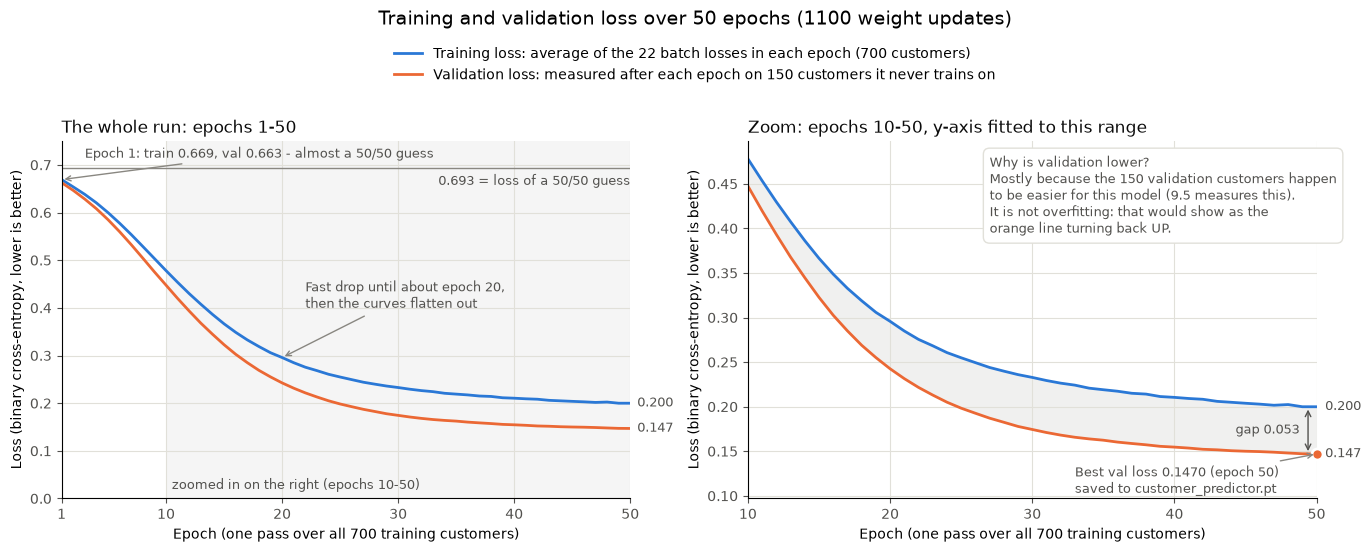

In [44]:
# Plot the loss that the training loop recorded after every epoch.
# Two views of the same numbers:
#   left:  the whole run (epochs 1-50), to see how far the loss came down
#   right: a zoom on epochs 10-50, with the y-axis fitted to that range, to see the
#          gap between the lines (in the full view the epoch-1 values stretch the y-axis)

# x values: train_loss_history[0] belongs to epoch 1, not epoch 0.
# plt.plot(train_loss_history) on its own numbers the points 0, 1, 2, ...,
# so every point would sit one epoch too far to the left.
epochs = list(range(1, len(train_loss_history) + 1))
last_epoch = epochs[-1]
best_epoch = val_loss_history.index(min(val_loss_history)) + 1  # epoch with the lowest val loss
ZOOM_START = 10  # first epoch shown in the zoomed view

# Colours: blue = training, orange = validation, in both views.
# Text stays dark grey; only the lines carry the colours.
TRAIN_COLOUR = "#2a78d6"
VAL_COLOUR = "#eb6834"
TEXT_COLOUR = "#52514e"
GRID_COLOUR = "#e1e0d9"
GUESS_LOSS = 0.693  # the loss of a 50/50 guess: -log(0.5)

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(14, 5.5))

for ax in (ax_full, ax_zoom):
    ax.plot(epochs, train_loss_history, color=TRAIN_COLOUR, linewidth=2)
    ax.plot(epochs, val_loss_history, color=VAL_COLOUR, linewidth=2)
    ax.set_xlabel("Epoch (one pass over all 700 training customers)")
    ax.set_ylabel("Loss (binary cross-entropy, lower is better)")
    ax.grid(True, color=GRID_COLOUR, linewidth=0.8)  # light, solid grid
    ax.spines[["top", "right"]].set_visible(False)  # remove the box around the plot
    ax.tick_params(colors=TEXT_COLOUR)

# --- Left: the whole run ---
ax_full.set_title("The whole run: epochs 1-50", loc="left", color="#0b0b0b")
ax_full.set_xlim(1, last_epoch)
ax_full.set_xticks([1, 10, 20, 30, 40, 50])
ax_full.set_ylim(0, 0.75)

# Reference line: a model that always answers 50/50 has a loss of 0.693
ax_full.axhline(GUESS_LOSS, color="#898781", linewidth=1)
ax_full.text(
    last_epoch, GUESS_LOSS - 0.012, "0.693 = loss of a 50/50 guess",
    ha="right", va="top", color=TEXT_COLOUR, fontsize=9,
)

# Start: both losses begin close to the 50/50 guess
ax_full.annotate(
    f"Epoch 1: train {train_loss_history[0]:.3f}, val {val_loss_history[0]:.3f}"
    " - almost a 50/50 guess",
    xy=(1, train_loss_history[0]), xytext=(3, 0.715),
    color=TEXT_COLOUR, fontsize=9, arrowprops=dict(arrowstyle="->", color="#898781"),
)

# Middle: where learning slows down
ax_full.annotate(
    "Fast drop until about epoch 20,\nthen the curves flatten out",
    xy=(20, train_loss_history[19]), xytext=(22, 0.40),
    color=TEXT_COLOUR, fontsize=9, arrowprops=dict(arrowstyle="->", color="#898781"),
)

# Shade the part that the right-hand view zooms into
ax_full.axvspan(ZOOM_START, last_epoch, color="#898781", alpha=0.08, linewidth=0)
ax_full.text(
    ZOOM_START + 0.5, 0.02, f"zoomed in on the right (epochs {ZOOM_START}-{last_epoch})",
    color=TEXT_COLOUR, fontsize=9,
)

# --- Right: zoom on epochs ZOOM_START-50, y-axis fitted to that range ---
zoom_train = train_loss_history[ZOOM_START - 1:]
zoom_val = val_loss_history[ZOOM_START - 1:]
ax_zoom.set_title(
    f"Zoom: epochs {ZOOM_START}-{last_epoch}, y-axis fitted to this range",
    loc="left", color="#0b0b0b",
)
ax_zoom.set_xlim(ZOOM_START, last_epoch)
ax_zoom.set_xticks([10, 20, 30, 40, 50])
ax_zoom.set_ylim(min(zoom_val) - 0.05, max(zoom_train) + 0.02)

# The gap between the two lines, shaded
ax_zoom.fill_between(
    epochs[ZOOM_START - 1:], zoom_train, zoom_val, color="#898781", alpha=0.12, linewidth=0
)
gap = train_loss_history[-1] - val_loss_history[-1]
ax_zoom.annotate(
    "", xy=(last_epoch - 0.6, val_loss_history[-1]),
    xytext=(last_epoch - 0.6, train_loss_history[-1]),
    arrowprops=dict(arrowstyle="<->", color=TEXT_COLOUR),
)
ax_zoom.text(
    last_epoch - 1.2, (train_loss_history[-1] + val_loss_history[-1]) / 2,
    f"gap {gap:.3f}", ha="right", va="center", color=TEXT_COLOUR, fontsize=9,
)
ax_zoom.text(
    27, max(zoom_train) + 0.005,
    "Why is validation lower?\n"
    "Mostly because the 150 validation customers happen\n"
    "to be easier for this model (9.5 measures this).\n"
    "It is not overfitting: that would show as the\n"
    "orange line turning back UP.",
    color=TEXT_COLOUR, fontsize=9, va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor=GRID_COLOUR),
)

# Best model: the epoch whose weights were saved to BEST_MODEL_PATH
ax_zoom.plot(
    best_epoch, min(val_loss_history), "o", markersize=8,
    color=VAL_COLOUR, markeredgecolor="white", markeredgewidth=2,
    clip_on=False,  # draw the whole dot, even at the edge of the plot
)
ax_zoom.annotate(
    f"Best val loss {min(val_loss_history):.4f} (epoch {best_epoch})\n"
    f"saved to {BEST_MODEL_PATH}",
    xy=(best_epoch, min(val_loss_history)), xytext=(33, min(val_loss_history) - 0.03),
    color=TEXT_COLOUR, fontsize=9, va="center",
    arrowprops=dict(arrowstyle="->", color="#898781"),
)

# Line-end values (right edge of both views)
for ax in (ax_full, ax_zoom):
    ax.text(last_epoch + 0.6, train_loss_history[-1], f"{train_loss_history[-1]:.3f}",
            va="center", color=TEXT_COLOUR, fontsize=9, clip_on=False)
    ax.text(last_epoch + 0.6, val_loss_history[-1], f"{val_loss_history[-1]:.3f}",
            va="center", color=TEXT_COLOUR, fontsize=9, clip_on=False)

# One legend for both views, saying what each line measures
fig.legend(
    handles=[
        plt.Line2D([], [], color=TRAIN_COLOUR, linewidth=2,
                   label="Training loss: average of the 22 batch losses in each epoch (700 customers)"),
        plt.Line2D([], [], color=VAL_COLOUR, linewidth=2,
                   label="Validation loss: measured after each epoch on 150 customers it never trains on"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=1, frameon=False, fontsize=10,
)
fig.suptitle("Training and validation loss over 50 epochs (1100 weight updates)", fontsize=14, y=0.995)

fig.tight_layout(rect=(0, 0, 1, 0.885))
plt.show()

### 9.5 Reading the loss chart

The chart draws the two lists that the training loop filled, one point per epoch: `train_loss_history` (blue) and `val_loss_history` (orange).

| Part of the chart | What it shows in this run |
|---|---|
| Left view, epochs 1–50 | The whole run. Both losses start at about 0.67, just below 0.693, the loss of a 50/50 guess (Section 8). They fall fast until about epoch 20, then flatten out, ending at **0.200** (training) and **0.147** (validation). |
| Right view, epochs 10–50 | The same two lines, with the y-axis fitted to 0.10–0.48. In the left view the epoch-1 values stretch the y-axis up to 0.7, so the end of the run is squeezed into the bottom. |
| Grey band between the lines | The gap between the training and validation loss: 0.053 at epoch 50. |
| Orange dot | The best validation loss, 0.1470 at epoch 50: the weights saved to `customer_predictor.pt`. |

**Two plotting details that are easy to get wrong**

- **The x values start at 1.** `plt.plot(train_loss_history)` with only one list numbers the points 0, 1, 2, ..., so epoch 1 is drawn at 0 and every point sits one epoch too far to the left. `plt.plot(epochs, train_loss_history)` with `epochs = 1, 2, ..., 50` puts each point at its real epoch.
- **A zoom needs both axes.** `plt.xlim(...)` on its own hides the early epochs but keeps the y-axis range of the whole run (up to 0.67), so the zoomed lines stay squeezed at the bottom with empty space above. The right view also sets the y-axis (`set_ylim`) to fit the values it shows. Change `ZOOM_START` in the code to zoom in from another epoch.

**Why are the two lines different?**

They measure different things, at different times, on different customers:

| | Training loss (blue) | Validation loss (orange) |
|---|---|---|
| Customers | the 700 training customers | 150 other customers, never trained on |
| When | **during** the epoch: the average of the 22 batch losses, while the weights are still changing | **after** the epoch, with the final weights |
| Mode | `model.train()` | `model.eval()` and `torch.no_grad()` |

To find out which difference makes the gap, an extra check (not part of the notebook code) also measured the training loss on all 700 customers **after** each epoch, in the same way as the validation loss. That splits the gap into two parts:

| Epoch | Training loss (average during the epoch) | Training loss (after the epoch) | Validation loss | Gap from timing | Gap from the customers |
|---|---|---|---|---|---|
| 1 | 0.669 | 0.661 | 0.663 | 0.008 | −0.001 |
| 5 | 0.600 | 0.588 | 0.585 | 0.012 | 0.003 |
| 10 | 0.478 | 0.465 | 0.448 | 0.013 | 0.017 |
| 20 | 0.296 | 0.289 | 0.243 | 0.007 | 0.046 |
| 50 | 0.200 | 0.199 | 0.147 | 0.001 | 0.052 |

- **Early on (epochs 1–10), timing matters.** The weights improve a lot within one epoch, so the epoch average still includes the worse, earlier batches.
- **From epoch 20 on, almost the whole gap comes from the customers.** The weights hardly change within an epoch any more (the timing part is about 0.001), but the 150 validation customers happen to be easier for this model. With the final weights it gets 95.3% of them right, against 91.9% of the training customers (and 92.7% of the test customers). With only 150 customers in a set, which customers end up in it makes a visible difference.

> **Overfitting looks different.** It shows as the orange line turning back **up** while the blue line keeps falling. Here both lines fall all the way to epoch 50, so the model is not overfitting.

### 9.6 Memory aid: batch vs epoch

![Batch vs epoch: each box is one batch of 32 customers, each row is one epoch of all 700 customers, and 50 rows make 1100 updates](images/epoch_batch_grid.svg)

**Think of studying a question bank with 700 practice questions:**

| Training word | Studying analogy | In this notebook |
|---|---|---|
| **Batch** | You do 32 questions, then check your answers. | 32 customers go through the model together. |
| **Iteration** (one update) | After checking, you fix what you got wrong. | `optimiser.step()` updates the 41 weights once. |
| **Epoch** | You have worked through all 700 questions once. | All 22 batches are done: every customer was seen once. |
| **50 epochs** | You go through the whole question bank 50 times, in a new order each time. | `num_epochs = 50`, and `shuffle=True` gives new batches each epoch. |

**The numbers to remember:**

```
batches per epoch = rows ÷ batch_size, rounded up   = 700 ÷ 32 = 21.9 → 22
total updates     = epochs × batches per epoch      = 50 × 22         = 1100
customers seen per epoch = all of them, once        = 700
```

> **In one line:** a batch is a **piece** of the data, an epoch is **all** of the data once. The weights change after every **batch**, not after every epoch.

**Test yourself:**

1. With `batch_size=64`, how many batches are in one epoch?
2. With `batch_size=32` and `num_epochs = 20`, how many times are the weights updated?
3. During one epoch, how many times does each customer go through the model?

<details>
<summary>Show the answers</summary>

1. 700 ÷ 64 = 10.9 → **11 batches** (10 batches of 64, and a last one of 60).
2. 20 × 22 = **440 updates**.
3. **Once.** That is what one epoch means.

</details>

# Stage 4 · Evaluate the Model

Give the best model its final, honest score on 150 test customers it has never seen. *Section 10.*

## 10. Evaluating the Model on the Test Set

Training is finished. Now the model gets its final, honest score on the **test set**: 150 customers it never trained on, and that played no part in choosing which weights to keep (that was the validation set's job). The test set is used **once**, here at the end.

| Step | Cell | What it does |
|---|---|---|
| 1 | Load the best weights | Reads `customer_predictor.pt` back into `model` |
| 2 | Predict | Gives each of the 150 test customers a probability and a label, 0 or 1 |
| 3 | Measure | Accuracy, confusion matrix and classification report (**10.1–10.3**) |
| 4 | Draw | The confusion matrix as a chart |

In [45]:
# Step 1: load the best model parameters from the file saved during training.
# Why: after the loop, `model` holds the weights from the LAST epoch. The best
# weights (lowest validation loss) were saved to BEST_MODEL_PATH in block 6, so
# they are read back here, before the model is evaluated on the test set.
# In this run the last epoch was also the best (val loss 0.1470 at epoch 50), so
# the weights do not change. In a run that overfits, they would.
try:
    # torch.load reads the file back into the state_dict that was saved: a dictionary
    # of the 4 weight and bias tensors (41 numbers). "ckpt" is short for checkpoint.
    #
    # map_location=torch.device("cpu"): every saved tensor remembers the device it
    #   was on (CPU or a GPU such as "cuda:0"), and torch.load puts it back on that
    #   same device. A file saved on a GPU machine would then fail to load on a
    #   laptop without a GPU ("Attempting to deserialize object on a CUDA device but
    #   torch.cuda.is_available() is False"). map_location moves every tensor to the
    #   CPU while loading, so the file loads on any machine. This model was trained
    #   on the CPU, so nothing moves here, but the line now also works for GPU files.
    #
    # weights_only=True: a .pt file is written with Python's pickle, and a pickle can
    #   hold code that runs while it is being loaded. A file from the internet could
    #   use this to run harmful code on your computer. weights_only=True only allows
    #   safe contents (tensors, numbers, strings, lists and dicts) and refuses
    #   anything else with an UnpicklingError. A state_dict is only tensors in a
    #   dict, so it loads fine. Since PyTorch 2.6 this is the default; writing it
    #   out makes the choice clear and keeps older versions safe too.
    ckpt = torch.load(
        BEST_MODEL_PATH, map_location=torch.device("cpu"), weights_only=True
    )
    print(f"Best model loaded from {BEST_MODEL_PATH}.")
except FileNotFoundError:
    # Cause: the file is not there, for example because it was deleted or moved,
    # or the notebook is running from a different folder, so the relative path
    # "customer_predictor.pt" points somewhere else.
    print(f"Best model file {BEST_MODEL_PATH} not found. Using the last trained model.")
    # Careful: `ckpt` is never created in this branch, so the load_state_dict line
    # below fails with NameError: name 'ckpt' is not defined. And if this cell ran
    # before, `ckpt` still holds those older weights, and they are loaded silently.

# load_state_dict copies the saved numbers into the model's existing layers.
# The names (hidden_layer.weight, ...) and shapes must match CustomerPredictor
# exactly. If they do not (for example the layer sizes or names were changed after
# saving), it raises a RuntimeError listing the missing/unexpected keys or the size mismatch.
model.load_state_dict(ckpt)  # load the weights into the model
print("Model weights loaded successfully.")

Best model loaded from customer_predictor.pt.
Model weights loaded successfully.


In [ ]:
# Step 2: predict the test set. `model` now holds the best weights (lowest validation
# loss), loaded in the cell above, ready for the final check on the 150 test customers.

# Why flatten the 2D arrays to 1D with .ravel()?
# The model returns its scores as one column, shape (150, 1), and the labels were
# reshaped to (150, 1) in Section 5 so that the loss function could compare them with
# the scores. The loss is not needed here, and a flat row of 150 labels, shape (150,),
# is easier and safer to use:
#   - Comparing works customer by customer. Comparing a (150,) array with a (150, 1)
#     array does NOT: NumPy "broadcasts" them into a (150, 150) table of every label
#     against every prediction, so counting the matches gives a wrong number, with no error.
#   - It prints as a few rows of 0s and 1s. A (150, 1) array prints one value per line.
#   - array[i] gives one number (0), not a 1-element row ([0]).
#   - (150,) is the usual shape for labels in NumPy and scikit-learn (accuracy_score,
#     confusion_matrix, ...), so the next steps can use these arrays directly.
#
#   (150, 1)  [[0], [1], [1], ...]   --.ravel()-->   (150,)  [0, 1, 1, ...]

model.eval()  # evaluation mode, as in the validation step of the training loop
with torch.no_grad():  # no backward() here, so autograd does not need to record anything
    # one raw score (logit) per test customer, shape (150, 1)
    test_logits = model(test_features_tensor)
    # sigmoid turns each raw score into the probability of label 1 (between 0 and 1).
    # .numpy() turns the tensor into a NumPy array; .ravel() flattens it from 2D
    # (150, 1) to 1D (150,), for the reasons above
    test_probabilities = torch.sigmoid(test_logits).numpy().ravel()

# The true labels: test_labels_tensor (Section 5) holds them as floats 0. / 1. with
# shape (150, 1). .ravel() flattens them to 1D (150,), the same shape as the
# predictions, and .astype(int) turns 0. / 1. into whole numbers 0 / 1
test_true_labels = test_labels_tensor.numpy().ravel().astype(int)
# A probability of 0.5 or more -> label 1, otherwise 0. This is the same rule as
# `batch_logits > 0` in the training loop, because sigmoid(0) = 0.5.
test_predicted_labels = (test_probabilities >= 0.5).astype(int)

print("Test set predictions:")
print("True labels:", test_true_labels)
print("Predicted labels:", test_predicted_labels)

Test set predictions:
True labels: [0 1 1 1 1 1 1 1 0 1 0 1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 1 0 0 0 0 1 0 1 1 0 0
 1 0 1 1 0 1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 1 1
 0 0 1 0 1 1 0 0 1 0 0 0 0 1 1 0 0 1 1 1 1 1 0 1 1 0 1 0 1 0 0 1 0 0 1 1 0
 0 0 1 1 0 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 1 0 1 1 1 0 0 0
 1 1]
Predicted labels: [0 1 0 1 1 1 1 1 0 1 0 1 0 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 0 1 0 1 1 0 0
 1 0 1 1 0 1 1 0 0 0 1 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 1
 0 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 0 1 0 0 1 0 0 1 1 0
 0 0 1 1 0 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 0
 1 1]


In [ ]:
# Step 3: measure the test predictions: accuracy, confusion matrix and classification report.
# All three compare the true labels with the predicted labels, customer by customer.
# scikit-learn's rule for the arguments: the TRUE labels first, the PREDICTED labels second.
CLASS_NAMES = ["will not buy (0)", "will buy (1)"]  # what label 0 and label 1 mean

# --- Accuracy: the share of the 150 test customers predicted correctly ---
# accuracy = correct predictions / all predictions
test_accuracy = accuracy_score(test_true_labels, test_predicted_labels)
# both arrays are 1D (150,), so == compares them customer by customer
correct_count = (test_true_labels == test_predicted_labels).sum()
print(
    f"Accuracy: {test_accuracy:.4f}"
    f" ({correct_count} of {len(test_true_labels)} test customers predicted correctly)"
)

# --- Confusion matrix: counts every combination of true and predicted label ---
# Rows are the true labels, columns are the predicted labels, both in the order 0, 1:
#                 predicted 0              predicted 1
#   true 0   [ true negatives  (TN)    false positives (FP) ]
#   true 1   [ false negatives (FN)    true positives  (TP) ]
# The diagonal (TN, TP) holds the right answers; the other two cells are the mistakes.
conf_matrix = confusion_matrix(test_true_labels, test_predicted_labels)
# .ravel() flattens the 2x2 matrix row by row, which gives the cells in this order
true_negatives, false_positives, false_negatives, true_positives = conf_matrix.ravel()
print("\nConfusion matrix (rows = true label, columns = predicted label):")
print(conf_matrix)
print(f"TN = {true_negatives}: non-buyers correctly predicted 'will not buy'")
print(f"FP = {false_positives}: non-buyers wrongly predicted 'will buy'")
print(f"FN = {false_negatives}: buyers wrongly predicted 'will not buy'")
print(f"TP = {true_positives}: buyers correctly predicted 'will buy'")

# --- Classification report: precision, recall and F1-score for each class ---
# Shown here for class 1 ("will buy"); class 0 uses the same rules with its own row and column.
#   precision = TP / (TP + FP)  when the model says "will buy", how often is it right?
#   recall    = TP / (TP + FN)  of all real buyers, how many did the model find?
#   f1-score  = 2 * precision * recall / (precision + recall)  one number balancing the two
#   support   = how many test customers really are in this class
# target_names puts readable names on the rows; digits=4 shows 4 decimals
print("\nClassification report:")
print(
    classification_report(
        test_true_labels, test_predicted_labels, target_names=CLASS_NAMES, digits=4
    )
)

Accuracy: 0.9267 (139 of 150 test customers predicted correctly)

Confusion matrix (rows = true label, columns = predicted label):
[[73  2]
 [ 9 66]]
TN = 73: non-buyers correctly predicted 'will not buy'
FP = 2: non-buyers wrongly predicted 'will buy'
FN = 9: buyers wrongly predicted 'will not buy'
TP = 66: buyers correctly predicted 'will buy'

Classification report:
                  precision    recall  f1-score   support

will not buy (0)     0.8902    0.9733    0.9299        75
    will buy (1)     0.9706    0.8800    0.9231        75

        accuracy                         0.9267       150
       macro avg     0.9304    0.9267    0.9265       150
    weighted avg     0.9304    0.9267    0.9265       150



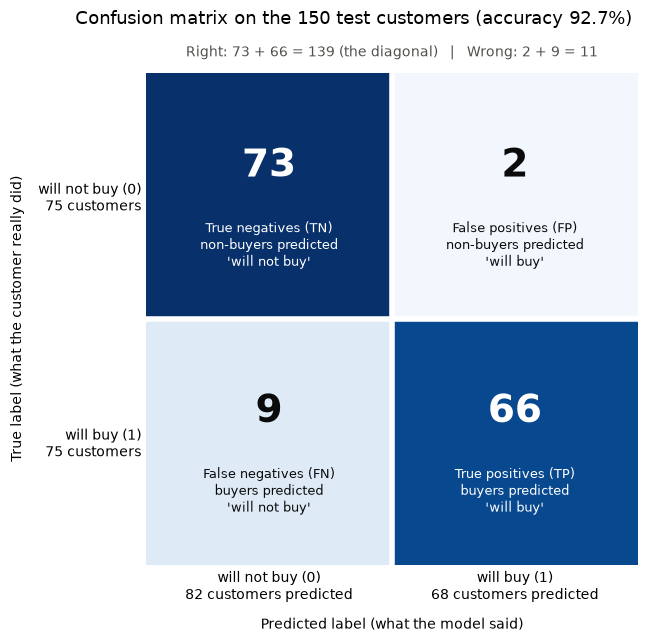

In [ ]:
# Step 4: draw the confusion matrix as a chart, so the four counts are easy to read.
# Darker blue = more customers. The diagonal (top left, bottom right) holds the right
# answers; the other two squares are the mistakes.
CELL_NAMES = [
    ["True negatives (TN)\nnon-buyers predicted\n'will not buy'",
     "False positives (FP)\nnon-buyers predicted\n'will buy'"],
    ["False negatives (FN)\nbuyers predicted\n'will not buy'",
     "True positives (TP)\nbuyers predicted\n'will buy'"],
]
row_totals = conf_matrix.sum(axis=1)  # customers really in each class: [75, 75]
column_totals = conf_matrix.sum(axis=0)  # customers predicted as each class: [82, 68]

fig, ax = plt.subplots(figsize=(8, 6.5))
# imshow colours each cell by its count, from light blue (0) to dark blue (the largest)
ax.imshow(conf_matrix, cmap="Blues", vmin=0, vmax=conf_matrix.max())

for row in range(2):
    for col in range(2):
        count = conf_matrix[row, col]
        # white text on the dark cells, dark text on the light ones
        text_colour = "white" if count > conf_matrix.max() / 2 else "#0b0b0b"
        ax.text(col, row - 0.12, str(count), ha="center", va="center",
                fontsize=28, fontweight="bold", color=text_colour)
        ax.text(col, row + 0.2, CELL_NAMES[row][col], ha="center", va="center",
                fontsize=9.5, color=text_colour)

# Axis labels: the class names, with how many customers each row and column holds
ax.set_xticks([0, 1])
ax.set_xticklabels(
    [f"{name}\n{total} customers predicted" for name, total in zip(CLASS_NAMES, column_totals)]
)
ax.set_yticks([0, 1])
ax.set_yticklabels(
    [f"{name}\n{total} customers" for name, total in zip(CLASS_NAMES, row_totals)]
)
ax.set_xlabel("Predicted label (what the model said)", labelpad=10)
ax.set_ylabel("True label (what the customer really did)", labelpad=10)

# Thin white lines between the four squares, and no frame around them
ax.axhline(0.5, color="white", linewidth=4)
ax.axvline(0.5, color="white", linewidth=4)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

wrong_count = false_positives + false_negatives
ax.set_title(
    f"Right: {true_negatives} + {true_positives} = {true_negatives + true_positives} (the diagonal)"
    f"   |   Wrong: {false_positives} + {false_negatives} = {wrong_count}",
    fontsize=10, color="#52514e", pad=12,
)
fig.suptitle(
    f"Confusion matrix on the {conf_matrix.sum()} test customers"
    f" (accuracy {test_accuracy:.1%})",
    fontsize=13,
)
fig.tight_layout()
plt.show()

### 10.1 Accuracy

$$\text{accuracy} = \frac{\text{correct predictions}}{\text{all predictions}} = \frac{139}{150} = 0.9267$$

The model predicts the right label for **92.7%** of the test customers. Compared with the other two sets, all measured with the same best weights:

| Set | Customers | Accuracy |
|---|---|---|
| Training | 700 | 91.9% |
| Validation | 150 | 95.3% |
| Test | 150 | **92.7%** |

- The test score is close to the training score, so the model works about as well on new customers as on the ones it learned from.
- The validation customers were the easiest of the three sets (see **9.5**), so the 95.3% there was higher than the model really scores on new customers. This is why the final score comes from a set that was never used to make a choice.
- **Accuracy alone can mislead.** Imagine 140 non-buyers and only 10 buyers: a model that always says "will not buy" scores 93% accuracy, but never finds a single buyer. Here the classes are balanced (75 and 75), so accuracy is a fair summary, but it still does not say *which* mistakes the model makes. The confusion matrix does.

### 10.2 The confusion matrix

| | Predicted 0: will not buy | Predicted 1: will buy | Total |
|---|---|---|---|
| **True 0: non-buyer** | **73** true negatives (TN) | **2** false positives (FP) | 75 |
| **True 1: buyer** | **9** false negatives (FN) | **66** true positives (TP) | 75 |
| **Total** | 82 | 68 | 150 |

- **Rows are the truth, columns are the prediction**, both in the order 0, 1. That is why `confusion_matrix` takes the true labels first. Swapping the two arguments flips the matrix, and FP and FN trade places.
- **"Positive" means label 1**, "will buy". A false positive is a wrong "will buy"; a false negative is a wrong "will not buy".
- `conf_matrix.ravel()` flattens the 2×2 matrix row by row into `[73, 2, 9, 66]`, which is TN, FP, FN, TP. That is how the code unpacks the four counts in one line.
- **The 11 mistakes are lopsided:** 9 missed buyers, but only 2 false alarms. The model is cautious about saying "will buy". Two of the missed buyers had probabilities of 0.497 and 0.492, just under the 0.5 threshold.
- **The threshold is a choice.** Lowering it from 0.5 (for example to 0.4) would catch more buyers, but also flag more non-buyers. Which mistake costs more depends on the business: a missed buyer is a lost sale, while a false alarm might waste a discount voucher.

### 10.3 The classification report

![Accuracy, precision and recall read from the confusion matrix: accuracy uses the diagonal, precision reads down the predicted-1 column, recall reads along the true-1 row](images/metrics_from_confusion_matrix.svg)

The report turns the confusion matrix into a score for each class:

| Row | precision | recall | f1-score | support |
|---|---|---|---|---|
| will not buy (0) | 73 ÷ 82 = 0.8902 | 73 ÷ 75 = 0.9733 | 0.9299 | 75 |
| will buy (1) | 66 ÷ 68 = 0.9706 | 66 ÷ 75 = 0.8800 | 0.9231 | 75 |

| Column | The question it answers, for "will buy" |
|---|---|
| **precision** | When the model says "will buy", how often is it right? 66 of its 68 "will buy" answers were right. |
| **recall** | Of all the real buyers, how many did the model find? 66 of the 75. |
| **f1-score** | One number that balances precision and recall (their harmonic mean). It is only high when **both** are high. |
| **support** | How many test customers really are in the class: 75 each. |

The bottom three rows summarise both classes:

| Row | What it is | Here |
|---|---|---|
| accuracy | correct ÷ all, the same number as 10.1 | 0.9267 |
| macro avg | the simple average of the two class rows | 0.9304, 0.9267, 0.9265 |
| weighted avg | the average weighted by support, so bigger classes count more | the same as macro avg, because both classes have 75 customers |

**What it says about this model:** for "will buy", precision (0.97) is higher than recall (0.88). When the model says "will buy" it is almost always right, but it misses 12% of the buyers. For "will not buy" it is the other way round: it finds 97% of the non-buyers, but 9 of its 82 "will not buy" answers were really buyers.

> **Memory aid:** **P**recision looks at the **P**redictions: a column, everyone the model *called* a buyer. **R**ecall looks at the **R**eal class: a row, everyone who *really is* a buyer.

# Stage 5 · Use the Model

Predict for a new customer: the reason the model was trained. *Section 11.*

## 11. Predicting for a New Customer

This is what the model was trained for: a new customer arrives, and the model predicts whether they will buy. The new customer goes through **exactly the same steps** as the training and test data:

a 2D row `[[1, 2, 3]]` → `feature_scaler.transform` (the training scaling) → a `float32` tensor → `model` → `torch.sigmoid` → the 0.5 rule

The cell below uses the raw features `[1, 2, 3]`. Change them to try other customers.

In [ ]:
# Predict for a new customer: the same steps as for the test set, for one row.
# The 3 numbers are raw (unscaled) feature values, like one row of `features` in Section 2.
# The double brackets matter: StandardScaler expects a 2D table of shape
# (customers, features), here 1 customer x 3 features = (1, 3). A flat list [1, 2, 3]
# is 1D and fails with "ValueError: Expected 2D array, got 1D array instead".
new_customer = [[1, 2, 3]]

# Scale with the scaler fitted on the training data: transform only, never fit again (4.1)
new_customer_scaled = feature_scaler.transform(new_customer)

# Convert to a float32 tensor of shape (1, 3), like the test features in Section 5
new_customer_tensor = torch.tensor(new_customer_scaled, dtype=torch.float32)

model.eval()  # evaluation mode, as for the test set
with torch.no_grad(): # no backward() here bcz we are not training, so autograd does not need to record anything
    new_customer_logit = model(new_customer_tensor)  # one raw score, shape (1, 1)
    # sigmoid turns the score into the probability of label 1; .item() turns the
    # 1-value tensor into a plain Python float
    new_customer_probability = torch.sigmoid(new_customer_logit).item()

# The same rule as for the test set: a probability of 0.5 or more -> label 1
new_customer_label = int(new_customer_probability >= 0.5)

print("Raw features:   ", new_customer[0])
print("Scaled features:", new_customer_scaled[0].round(4))
print(f"Raw score (logit): {new_customer_logit.item():.4f}")
print(f"Probability of 'will buy': {new_customer_probability:.4f}")
print(f"Prediction: {new_customer_label} -> {CLASS_NAMES[new_customer_label]}")

Raw features:    [1, 2, 3]
Scaled features: [0.8108 2.0017 1.9681]
Raw score (logit): 6.6188
Probability of 'will buy': 0.9987
Prediction: 1 -> will buy (1)


### 11.1 Reading the prediction, step by step

Each step, with the values for the customer `[1, 2, 3]`:

| Step | Code | Result |
|---|---|---|
| 1. A 2D table | `[[1, 2, 3]]` | 1 customer × 3 features, shape `(1, 3)` |
| 2. Scale | `feature_scaler.transform(...)` | `[0.81, 2.00, 1.97]`: each value minus the training mean, divided by the training std |
| 3. Tensor | `torch.tensor(..., dtype=torch.float32)` | shape `(1, 3)` |
| 4. Model | `model(...)` | raw score (logit) 6.62 |
| 5. Sigmoid | `torch.sigmoid(...)` | probability 0.9987 |
| 6. Threshold | `>= 0.5` | label 1, "will buy" |

- **Why the double brackets?** scikit-learn always works on tables: rows are customers, columns are features. From a flat list `[1, 2, 3]` it cannot tell whether that is 1 customer with 3 features or 3 customers with 1 feature, which is what the `reshape(1, -1)` hint in the error message is about. `[[1, 2, 3]]` makes it clear: one row. `np.array([1, 2, 3]).reshape(1, -1)` gives the same shape. **5.3** explains why the input must be 2D.
- **Why `transform` and not `fit_transform`?** The model learned from features scaled with the training mean and std (**4.1**). A new customer must be scaled by the same rule, and one row has no useful mean or std of its own.
- **Reading the result:** the scaled values 2.00 and 1.97 mean features 2 and 3 are about 2 standard deviations above the training average, and the model is very confident this customer will buy (0.9987). All three raw values lie inside the range of the training data (each feature there runs from about −4 to between +2.9 and +4.6), so the model has seen similar customers. For a customer far outside that range, the model would still give a confident-looking probability, but it would mean much less.

# Summary · The Training Workflow on One Page

| Stage | Sections | Key code | Result in this run |
|---|---|---|---|
| 1. Prepare the data | 1–6 | `make_classification`, `train_test_split`, `StandardScaler`, `torch.tensor(..., dtype=torch.float32)`, `DataLoader(..., batch_size=32, shuffle=True)` | 700 / 150 / 150 customers; 22 mini-batches of 32 per epoch |
| 2. Set up the model, loss and optimiser | 7–8 | `CustomerPredictor()`, `nn.BCEWithLogitsLoss()`, `optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)` | a 3 → 8 → 1 network with 41 parameters |
| 3. Train the model | 9 | `zero_grad()` → `model(...)` → `loss_function(...)` → `backward()` → `step()`, then validation with `model.eval()` and `torch.no_grad()`, and `torch.save(...)` for the best weights | 50 epochs, 1100 weight updates; best validation loss 0.1470 |
| 4. Evaluate the model | 10 | `model.load_state_dict(torch.load(...))`, `accuracy_score`, `confusion_matrix`, `classification_report` | test accuracy 92.7% (139 of 150 customers) |
| 5. Use the model | 11 | a 2D row → `feature_scaler.transform` → tensor → `model` → `torch.sigmoid` → `>= 0.5` | `[1, 2, 3]` → probability 0.9987 → "will buy" |

> **Neural network training in one sentence:** for every mini-batch, run the *forward pass*, measure the *loss*, run the *backward pass* and take an *optimiser step*; repeat for many epochs, and let a separate validation set decide which weights to keep.